In [59]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from plots import *
from helper import *
import joblib

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OrdinalEncoder, TargetEncoder, OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from category_encoders import CountEncoder

In [4]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate, train_test_split

In [5]:
df_prices = pd.read_csv("C:/Users/redli/OneDrive/Desktop/classic ml tasks/regression/Hourly_Gasoline_Prices.csv")
df_fuel_st_info = pd.read_csv(r"C:\Users\redli\OneDrive\Desktop\classic ml tasks\regression\Fuel_Station_Information.csv")
df_full_eda = pd.merge(df_prices, df_fuel_st_info, how = "inner", on = "Id")
df_full_eda = df_full_eda.drop_duplicates()
df_full_eda.head(30)

,Id,isSelf,Price,Date,Fuel_station_manager,Petrol_company,Type,Station_name,City,Latitude,Longitudine
0,51169,1,1.943,2022-01-01 11:45:53,AURA PETROLSERVICE S.N.C. DI LANZA BRUNO & C.,Api-Ip,Autostradale,BAUDUCCHI OVEST,MONCALIERI,44.977978,7.700216
1,44566,1,1.725,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323
2,44566,0,1.775,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323
3,20026,1,1.729,2022-01-02 11:27:01,FIARDI TRADING - SOCIETA' A RESPONSABILITA' LI...,Api-Ip,Stradale,IP,CAMPOMARINO,41.938508,15.076976
4,12494,0,1.559,2022-01-02 12:07:25,BUSSINELLO S.R.L.,Pompe Bianche,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766
5,12494,1,1.559,2022-01-02 12:07:25,BUSSINELLO S.R.L.,Pompe Bianche,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766
6,37593,0,1.789,2022-01-02 12:36:25,CARBURANTI PALAZZO S.N.C.,Ies,Stradale,CARBURANTI PALAZZO SNC,BARANELLO,41.516827,14.594655
7,37593,1,1.789,2022-01-02 12:36:25,CARBURANTI PALAZZO S.N.C.,Ies,Stradale,CARBURANTI PALAZZO SNC,BARANELLO,41.516827,14.594655
8,50047,0,1.879,2022-01-02 14:20:37,DI BENEDETTO MARIA AGATA,SP Energia Siciliana,Stradale,stzione di servizio Di Benedetto Maria Agata,VENTIMIGLIA DI SICILIA,37.920051,13.565093
9,52185,0,1.800,2022-01-02 17:25:08,PIRA GIANPAOLO,Q8,Stradale,PIRA GIANPAOLO,BITTI,40.476894,9.382334


In [6]:
df_full_eda.to_csv('df_full_eda.csv', index=False)

In [60]:
comparable_lgbm = joblib.load("base_line.joblib")["metrics"]

In [7]:
from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV, Lasso, Ridge, ElasticNet, ElasticNetCV
from sklearn.ensemble import GradientBoostingRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from xgboost import XGBRegressor, XGBRFRegressor
import optuna

In [8]:
'''from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml import Pipeline as pipiline
from pyspark.ml.feature import OneHotEncoder, StandardScaler, TargetEncoder, VectorAssembler, SQLTransformer
from pyspark.sql.window import Window
from pyspark.ml import Transformer'''

'from pyspark.sql import SparkSession\nfrom pyspark.sql import functions as F\nfrom pyspark.ml import Pipeline as pipiline\nfrom pyspark.ml.feature import OneHotEncoder, StandardScaler, TargetEncoder, VectorAssembler, SQLTransformer\nfrom pyspark.sql.window import Window\nfrom pyspark.ml import Transformer'

Вместо обычно randomforest использовался xgbrfregressor, так как его можно обучать на винде при помощи GPU

In [9]:
'''spark = SparkSession.builder.appName("HP_tunn").getOrCreate()
sampler_cols = ["Date", "Time", "Longitudine", "Latitude"]
spark = SparkSession.builder.appName("HP_tunn").getOrCreate()

sdf = spark.read.csv("df_full_eda.csv")

cols = list(df_full_eda.columns[:-1])
print(cols)

sql_transformer = SQLTransformer(statement= f"""
                SELECT *, 
                dayofyear(to_timestamp(Date)) AS day_of_year,
                hour(to_timestamp(Date)) * 60 + minute(to_timestamp(Date)) AS minute_of_year,
                array(coalscense(City, "Missing") AS City
                array(coalscense(Fuel_station_manager, 'MISSING')) AS Fuel_station_manager
                FROM __THIS__
""")

spark_pipline = pipiline(stages=[
    VectorAssembler(inputCols = sampler_cols, outputCol="scaler_features"),
    sql_transformer,
    StandardScaler(withMean = True, withStd = True, inputCol = "scaler_features"),
    OneHotEncoder(inputCols = ["Type"]),
    TargetEncoder(inputCols = ["Fuel_station_manager"]),
    TargetEncoder(inputCols = ["Petrol_company"]),
    VectorAssembler(inputCols = cols, outputCol="features"),
    LinearRegression()
]   
)'''

'spark = SparkSession.builder.appName("HP_tunn").getOrCreate()\nsampler_cols = ["Date", "Time", "Longitudine", "Latitude"]\nspark = SparkSession.builder.appName("HP_tunn").getOrCreate()\n\nsdf = spark.read.csv("df_full_eda.csv")\n\ncols = list(df_full_eda.columns[:-1])\nprint(cols)\n\nsql_transformer = SQLTransformer(statement= f"""\n                SELECT *, \n                dayofyear(to_timestamp(Date)) AS day_of_year,\n                hour(to_timestamp(Date)) * 60 + minute(to_timestamp(Date)) AS minute_of_year,\n                array(coalscense(City, "Missing") AS City\n                array(coalscense(Fuel_station_manager, \'MISSING\')) AS Fuel_station_manager\n                FROM __THIS__\n""")\n\nspark_pipline = pipiline(stages=[\n    VectorAssembler(inputCols = sampler_cols, outputCol="scaler_features"),\n    sql_transformer,\n    StandardScaler(withMean = True, withStd = True, inputCol = "scaler_features"),\n    OneHotEncoder(inputCols = ["Type"]),\n    TargetEncoder(inputCol

Я ЕГО СДЕЛАЛ!!! Отсюда убирать не буду, мне жалко( Клод сказал, что это все не правильно и это все не ускорит процесс, я замер, так и оказалось, он предложил убрать KNNImputer и избавиться от лямбды функции, это надеюсь поможет не обучать модель в течении часа

In [26]:
from funcs import datetime_processing_func
from feature_engine.encoding import RareLabelEncoder

In [54]:
dt_proc = FunctionTransformer(datetime_processing_func)
base_line = Pipeline(
                         [("fill_na_knn", ColumnTransformer(
                                                              [
                                                                ("fill_na_city", SimpleImputer(strategy="constant", fill_value = "Missing"), ["City"]),
                                                                ("fill_na_cords", SimpleImputer(strategy="mean"), ["Latitude", "Longitudine"]),
                                                              ],
                                                              remainder = "passthrough", verbose_feature_names_out=False
                                                            )),
                           ("dt_proc", dt_proc),
                           ("noise_proc", RareLabelEncoder(variables = ["Fuel_station_manager", "City"], tol=0.00005, n_categories=1, replace_with="Other")),
                           ("transformer", ColumnTransformer(
                                                              [
                                                                ("drop", "drop", ["Station_name"]),
                                                                ("city_encoder", CountEncoder(normalize=True, handle_unknown=0, handle_missing="value"), ["City"]),
                                                                ("manager_encoder", TargetEncoder(smooth='auto', cv=5), ["Fuel_station_manager"]), 
                                                                ("company_encoder", TargetEncoder(smooth='auto', cv=5), ["Petrol_company"]),
                                                                ("type_encoder", OneHotEncoder(drop = "first", sparse_output=False), ["Type"]),
                                                              ],
                                                              remainder = "passthrough", verbose_feature_names_out=False
                                                             )
                           ),
                           ("scaler", "passthrough"),
                           ("model", "passthrough")
                          ]
                         ) 
base_line.set_output(transform = "pandas")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('fill_na_knn', ...), ('dt_proc', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('fill_na_city', ...), ('fill_na_cords', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out v

In [12]:
models_w_tunned_params = {}

Для тюнинга параметров будет использована Optuna, она позволяет не перебирать напрямую все параметры, а выделять диапазон значений параметров, для которых скор наиболее высокий и останавливаться на них

In [13]:
from sklearn.base import clone
import optuna

In [14]:
def lasso(trial):
    return {"alpha" : trial.suggest_float("alpha", 0.01, 1, log=True)}
    
def ridge(trial):
    return {"alpha" : trial.suggest_float("alpha", 0.01, 1, log=True)}
    
def elasticnet(trial):
    return {"alpha" : trial.suggest_float("alpha", 0.01, 1, log=True), 
            "l1_ratio" : trial.suggest_float("l1_ratio", 0.05, 1.0, log=False),
           }
def rndforest(trial):
    return {"n_estimators" : trial.suggest_int("n_estimators", 100, 1000, step=100),
            "max_depth" : trial.suggest_int("max_depth", 3, 10),
            "min_child_weight" : trial.suggest_int("min_child_weight", 1, 5),
           }
def lgbm(trial):
    return {"learning_rate" : trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "n_estimators" : trial.suggest_int("n_estimators", 100, 1000, step=100),
            "min_child_samples" : trial.suggest_int("min_child_samples", 100, 1000, step=100),
            "num_leaves": trial.suggest_int("num_leaves", 15, 255, log=True),
           }
def xgboost(trial):
    return {"learning_rate" : trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "n_estimators" : trial.suggest_int("n_estimators", 100, 1000, step=100),
            "max_depth" : trial.suggest_int("max_depth", 3, 10), 
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
           }
def catboost(trial):
    return {"learning_rate" : trial.suggest_float("learning_rate", 0.01, 0.3, log=True), 
            "depth": trial.suggest_int("depth", 6, 10),
            "l2_leaf_reg": trial.suggest_int("l2_leaf_reg", 1, 30, log=True),
            "random_strength": trial.suggest_int("random_strength", 0, 5),
            "subsample" : trial.suggest_float("subsample", 0.5, 0.9, step = 0.1),
            "one_hot_max_size": trial.suggest_int("one_hot_max_size", 2, 30),
            "iterations" : trial.suggest_int("iterations", 500, 3000, step =100),
           }
param_grids = {
    "lgbm_model": lgbm,
    "xgboost_model": xgboost,
    "catboost_model": catboost,
}

In [15]:
models = {
"lgbm_model" : LGBMRegressor(),
"catboost_model" : CatBoostRegressor(loss_function="RMSE",
                          eval_metric="MAE", bootstrap_type="Bernoulli", verbose=0, task_type="GPU", devices="0",),
"xgboost_model" : XGBRegressor(device="cuda",)}

Все эти модели были в пайплайне на обучение, но от большинства я избавился, чтобы по несколько кругов не проверять, что самый лучшие метрики у лайт и катбуста

In [16]:
df_full_eda = df_full_eda.drop_duplicates().sort_values("Date").reset_index(drop=True)
split_idx = int(len(df_full_eda) * 0.8)
df_learning, df_check = df_full_eda.iloc[:split_idx], df_full_eda.iloc[split_idx:]

drop_cols = ["Price", "Id"]
X_train, y_train = df_learning.drop(drop_cols, axis = 1), df_learning["Price"]
X_test,  y_test  = df_check.drop(drop_cols, axis = 1),    df_check["Price"]


cv = TimeSeriesSplit(n_splits = 5)
folds = []

print(cv.split(X_train, y_train))
for step, (tr, vl) in enumerate(cv.split(X_train, y_train)):
    pipe = clone(base_line)
    X_tr = pipe.fit_transform(X_train.iloc[tr], y_train.iloc[tr])
    X_vl = pipe.transform(X_train.iloc[vl])
    folds.append([X_tr, y_train.iloc[tr].to_numpy(), X_vl, y_train.iloc[vl].to_numpy()])

<generator object TimeSeriesSplit._split at 0x0000011953B1C720>


In [17]:
folds[0][0].head()

,City,Fuel_station_manager,Petrol_company,Type_Stradale,isSelf,Date,Latitude,Longitudine,Time
0,0.000983,1.860443,1.838785,0.0,1,1,44.977978,7.700216,705
1,0.000413,1.860762,1.865606,1.0,1,2,40.059118,18.032323,675
2,0.000413,1.860476,1.865770,1.0,0,2,40.059118,18.032323,675
3,0.000291,1.860274,1.837460,1.0,1,2,41.938508,15.076976,687
4,0.000276,1.750488,1.806009,1.0,0,2,45.386059,11.273766,727


In [18]:
def objective(trial, model_name, model):
    params = param_grids[model_name](trial)
    scores = []
    for step, (X_tr, y_tr, X_vl, y_vl) in enumerate(folds):
        fold_model = clone(model).set_params(**params)
        fold_model.fit(X_tr, y_tr)
        scores.append(fold_model.score(X_vl, y_vl))
                     
        trial.report(np.mean(scores), step)
        if trial.should_prune():
            raise optuna.TrialPruned()
    return np.mean(scores)

studies = {}

for model_name in param_grids.keys():
    model = models[model_name]

    study = optuna.create_study(
        direction="maximize",
        study_name=model_name,
        sampler=optuna.samplers.TPESampler(seed=42),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1),
    )
    study.optimize(
        lambda trial: objective(trial, model_name, model),
        n_trials=30,
        timeout=1800,
    )
    studies[model_name] = study
    print(f"{model_name}: R² = {study.best_value:.4f}, {study.best_params}")

[I 2026-11-25 16:09:55,061] A new study created in memory with name: lgbm_model


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002016 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1596
[LightGBM] [Info] Number of data points in the train set: 319284, number of used features: 9
[LightGBM] [Info] Start training from score 1.834126
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004561 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1614
[LightGBM] [Info] Number of data points in the train set: 638564, number of used features: 9
[LightGBM] [Info] Start training from score 1.825438
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004512 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enoug

[I 2026-11-25 16:11:00,760] Trial 0 finished with value: -0.17431669343116324 and parameters: {'learning_rate': 0.03574712922600244, 'n_estimators': 1000, 'min_child_samples': 800, 'num_leaves': 81}. Best is trial 0 with value: -0.17431669343116324.


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001496 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1596
[LightGBM] [Info] Number of data points in the train set: 319284, number of used features: 9
[LightGBM] [Info] Start training from score 1.834126
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004638 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1614
[LightGBM] [Info] Number of data points in the train set: 638564, number of used features: 9
[LightGBM] [Info] Start training from score 1.825438
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004588 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enoug

[I 2026-11-25 16:11:18,705] Trial 1 finished with value: -0.2922442968989648 and parameters: {'learning_rate': 0.01700037298921102, 'n_estimators': 200, 'min_child_samples': 100, 'num_leaves': 174}. Best is trial 0 with value: -0.17431669343116324.


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001583 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1596
[LightGBM] [Info] Number of data points in the train set: 319284, number of used features: 9
[LightGBM] [Info] Start training from score 1.834126
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004944 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1614
[LightGBM] [Info] Number of data points in the train set: 638564, number of used features: 9
[LightGBM] [Info] Start training from score 1.825438
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004285 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enoug

... (56 outputs left out)

C:\Users\redli\AppData\Local\Programs\Python\Python314\Lib\site-packages\xgboost\core.py:569: UserWarning: [16:25:40] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)
[I 2026-11-25 16:26:10,814] Trial 0 finished with value: -0.09078450915941452 and parameters: {'learning_rate': 0.03574712922600244, 'n_estimators': 1000, 'max_depth': 8, 'reg_lambda': 0.24810409748678125}. Best is trial 0 with value: -0.09078450915941452.
[I 2026-11-25 16:26:14,983] Trial 1 finished with value: -0.31739223728942545 and parameters: {'learning_rate': 0.01700037298921102, 'n_

xgboost_model: R² = -0.0804, {'learning_rate': 0.08646655501267565, 'n_estimators': 900, 'max_depth': 6, 'reg_lambda': 0.44688402263097754}


Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
[I 2026-11-25 16:32:43,934] Trial 0 finished with value: -0.14595559715332265 and parameters: {'learning_rate': 0.03574712922600244, 'depth': 10, 'l2_leaf_reg': 10, 'random_strength': 3, 'subsample': 0.5, 'one_hot_max_size': 6, 'iterations': 600}. Best is trial 0 with value: -0.14595559715332265.
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
[I

catboost_model: R² = -0.0564, {'learning_rate': 0.14471066576795344, 'depth': 7, 'l2_leaf_reg': 8, 'random_strength': 4, 'subsample': 0.7, 'one_hot_max_size': 26, 'iterations': 3000}


In [27]:
studies_copy = studies.copy()

In [28]:
studies = studies_copy.copy()

In [29]:
for model_name, results in studies.items():
     print(f"{model_name}: R² = {results}")

lgbm_model: R² = <optuna.study.study.Study object at 0x0000011952E702F0>
xgboost_model: R² = <optuna.study.study.Study object at 0x0000011951390410>
catboost_model: R² = <optuna.study.study.Study object at 0x0000011952F634D0>


In [30]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score, mean_absolute_percentage_error, root_mean_squared_error

Чтобы не проходить подбор параметров каждый раз по новой, засуну значения явно через дикты

In [31]:
result_models = models
result_models

{'lgbm_model': LGBMRegressor(),
 'catboost_model': CatBoostRegressor(bootstrap_type='Bernoulli', devices='0', eval_metric='MAE', loss_function='RMSE', task_type='GPU', verbose=0),
 'xgboost_model': XGBRegressor(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device='cuda', early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)}

In [32]:
list(folds[0][0].columns)

['City',
 'Fuel_station_manager',
 'Petrol_company',
 'Type_Stradale',
 'isSelf',
 'Date',
 'Latitude',
 'Longitudine',
 'Time']

In [33]:
target_mean = df_full_eda["Price"].mean()
result_metrics = {}
for name, model in result_models.items():
    model = clone(model)
    result_metrics[name] = {"R2" : [], "MAPE" : [], "RMSE": []}
    for fold in folds:
          model.fit(fold[0], fold[1])
          y_pred = model.predict(fold[2])
          result_metrics[name]["R2"].append(r2_score(fold[3], y_pred))
          result_metrics[name]["MAPE"].append(mean_absolute_percentage_error(fold[3], y_pred))
          result_metrics[name]["RMSE"].append(root_mean_squared_error(fold[3], y_pred))
    result_metrics[name]["R2"] = np.mean(result_metrics[name]["R2"])
    result_metrics[name]["MAPE"] = np.mean(result_metrics[name]["MAPE"])
    result_metrics[name]["RMSE"] = np.mean(result_metrics[name]["RMSE"])
    print(f"{name}: "
          f"R2 {result_metrics[name]["R2"]:.4f} | "
          f"MAPE {result_metrics[name]["MAPE"]:.4f} | "
          f"RMSE {result_metrics[name]["RMSE"]:.4f}" )

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001504 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1596
[LightGBM] [Info] Number of data points in the train set: 319284, number of used features: 9
[LightGBM] [Info] Start training from score 1.834126
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004656 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1614
[LightGBM] [Info] Number of data points in the train set: 638564, number of used features: 9
[LightGBM] [Info] Start training from score 1.825438
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004602 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enoug

Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU


catboost_model: R2 -0.0832 | MAE 0.0610 | RMSE 0.1560
xgboost_model: R2 -0.1058 | MAE 0.0615 | RMSE 0.1576


In [34]:
target_mean = df_full_eda["Price"].mean()

pipe = clone(base_line)

In [35]:
df_result_metrics = pd.DataFrame(result_metrics).set_axis(["R2", "MAPE", "RMSE"], axis=0).T
df_result_metrics

,R2,MAPE,RMSE
lgbm_model,-0.165024,0.063190,0.161765
catboost_model,-0.083216,0.060960,0.156037
xgboost_model,-0.105824,0.061483,0.157559


<Axes: >

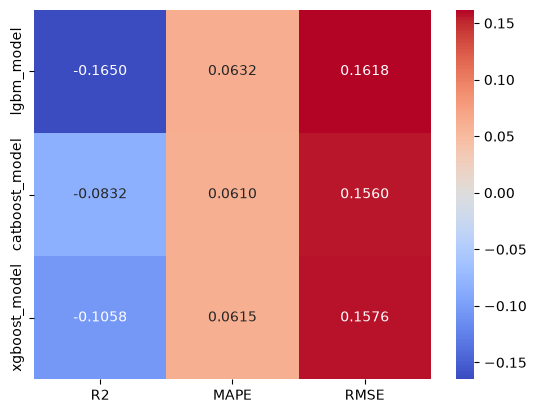

In [36]:
sns.heatmap(df_result_metrics, annot=True, cmap='coolwarm', fmt='.4f')

In [37]:
diff_after_ht = pd.DataFrame()
for score in ["MAPE", "R2", "RMSE"]:
    diff_after_ht[score] = df_result_metrics[score] - comparable_lgbm[score]

<Axes: >

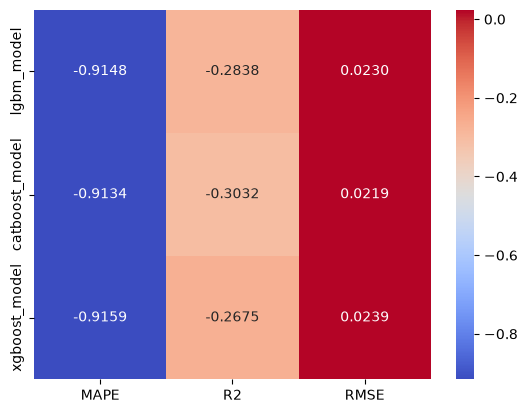

In [65]:
sns.heatmap(diff_after_ht, annot=True, cmap='coolwarm', fmt='.4f')

Резльтаты не впечатляют, но это этап тюнинга параметров, с разбиением на временные ряды + новые значения не имеют данных о предыдущих

In [38]:
print(df_result_metrics.loc["xgboost_model"])
print(df_result_metrics.loc["lgbm_model"])
print(df_result_metrics.loc["catboost_model"])

R2     -0.105824
MAPE    0.061483
RMSE    0.157559
Name: xgboost_model, dtype: float64
R2     -0.165024
MAPE    0.063190
RMSE    0.161765
Name: lgbm_model, dtype: float64
R2     -0.083216
MAPE    0.060960
RMSE    0.156037
Name: catboost_model, dtype: float64


In [55]:
import joblib

In [56]:
pipe = clone(base_line)

In [57]:
bundle = {
        "lgbm_model": result_models["lgbm_model"],
        "pipeline": pipe,
        "xgboost": result_models["lgbm_model"],
        "metrics" : df_result_metrics.loc["lgbm_model"] 
}

In [58]:
joblib.dump(bundle, "hptunned.joblib")

['hptunned.joblib']